# Opportunity audit for a substantial improvement

Current user-confirmed public AUC: **0.76824**. The user reports top-ten scores
displayed as 1 and top-twenty scores above 0.8, with uncertain methods/data
provenance. This motivates a competitive target, not a claim that 0.8 is
achievable from the allowed inputs. This notebook analyzes saved predictions;
no new model is fitted and no prediction is adjusted.

All nine pre-existing notebooks remain unchanged. The incremental round-four
search was stopped after seven completed screens at the user's priority change.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'input/train.csv').exists())
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
HERE=ROOT/'improvements/high_upside';ART=HERE/'artifacts'
summary=json.loads((ART/'audit_summary.json').read_text())
assert hashlib.sha256((HERE/'opportunity_audit.py').read_bytes()).hexdigest()==summary['source_sha256']
print('Python:',sys.executable)
display(summary)
display(Markdown((HERE/'OPPORTUNITY_AUDIT_PLAN.md').read_text()))

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python


{'reference': 'Frozen round-three three-seed development OOF recipe',
 'auc': 0.7648034854637242,
 'rows': 136961,
 'positives': 11057,
 'positive_negative_pairs': 1392120528,
 'global_pair_loss': 0.23519651453627577,
 'data_sha256': 'b8dd5a61771d8eb2821972c1b7d3f2f747cc66471f4d34153036d2d9c458ecf1',
 'split_sha256': '5edf2b0fd97c608ca1213e3870f64a719cc8c2e971f1174d5ef8085088f54121',
 'prediction_sha256': 'e2f80818c8560a72e5815952debd961b068127015a038428d4f0d15a09652484',
 'source_sha256': 'be063c48c58bf69e3312486ae329851de50b359ca5968472c5380c60d34e8738',
 'saved_capacity_diagnostic': {'model': 'improvements/round3/models/r3_cat_signed_s0_fold0.cbm',
  'own_training_sample_rows': 20000,
  'heldout_rows': 34241,
  'own_training_sample_auc': 0.81409251455652,
  'heldout_auc': 0.7651793349951106,
  'caution': 'One saved model and a sampled training subset. In-sample performance is optimistic, not validation; this cannot identify the attainable AUC ceiling.'},
 'no_models_fitted': True,
 

# Opportunity audit, before new model fitting

Reference: the frozen three-seed round-three development OOF predictions, aligned
to the unchanged development rows. The same labels have been explored before;
these are descriptive hypothesis-generation results, not independent validation.
No model fitting, learned combiner or prediction adjustment occurs in this audit.

Questions:

1. Which sufficiently large supplied-data groups account for lost positive-negative
   pair orderings? Decompose `1 - AUC` into disjoint positive-group / negative-group
   cells for external-score absence, contract, income, education and age groups.
   Sum cells back to the exact global pair loss. This avoids selecting a small
   group merely because its within-group AUC looks poor.
2. Is the error mainly within a group or between groups? Report both and the
   share of total loss. Any theoretical removable pair loss is only an optimistic
   descriptive bound; it is not an attainable prediction rule or a model forecast.
3. Do group means exhibit substantial calibration residuals, and are scores
   missing in the high-contribution groups? Sparse groups are flagged. This can
   motivate a learned representation or segment model, never hand-labeling.
4. Is obvious missing capacity a plausible explanation? On a saved CatBoost model,
   compare a deterministic sample of its own training rows with its cached held-out
   rows. This single-model in-sample diagnostic is not a performance estimate and
   cannot establish a statistical ceiling.

Output: exact evidence tables, code/data/prediction hashes, a new notebook and
shortlist of hypotheses with measured motivation. No additional data, external
labels, recovered identities, pretrained weights or changes to older notebooks.

Leaderboard feedback is recorded separately as user-reported and unverified with
respect to methods/rule compliance: top ten displayed 1; top twenty above 0.8.


## Where ranking errors occur

AUC is the fraction of positive-negative pairs ordered correctly, with half
credit for ties. Each matrix cell below contributes a fraction of **all**
positive-negative pairs to `1 - AUC`. Rows identify the positive applicant's
group; columns identify the negative applicant's group. Cells sum exactly to
the reference's global loss. Diagonal cells describe errors within groups.
Off-diagonal cells describe cross-group errors.

These are error attributions, not achievable improvements. Correcting every
selected pair independently may not correspond to any consistent score order.

In [2]:
cells=pd.read_csv(ART/'pair_loss_cells.csv',dtype={'positive_group':str,'negative_group':str})
slices=pd.read_csv(ART/'group_slices.csv',dtype={'value':str})
components=pd.read_csv(ART/'within_between_loss.csv')
for name,frame in cells.groupby('group'):
    assert abs(frame.global_auc_loss.sum()-summary['global_pair_loss'])<1e-12,name
display(components)
display(slices[slices.group=='EXT_missing_count'])
display(slices[slices.group=='NAME_CONTRACT_TYPE'])

,group,within_auc_loss,between_auc_loss,within_share_of_loss,groups
0,NAME_CONTRACT_TYPE,0.200518,0.034679,0.852554,2
1,NAME_INCOME_TYPE,0.092689,0.142507,0.394092,8
2,NAME_EDUCATION_TYPE,0.143582,0.091614,0.610478,5
3,CODE_GENDER,0.125376,0.109820,0.533071,3
4,EXT_missing_count,0.096549,0.138648,0.410503,4
5,EXT_missing_pattern,0.075247,0.159949,0.319934,8
6,age_band,0.052941,0.182256,0.225091,5


,group,value,rows,positives,negatives,positive_rate,mean_prediction,calibration_residual,auc,within_auc_loss,positive_centered_auc_loss,negative_centered_auc_loss,loss_involving_group,positive_share_of_total_loss,sparse
18,EXT_missing_count,0,28971,2050,26921,0.070760,0.069771,0.000989,0.775382,8.904566e-03,0.048427,0.042950,0.082473,0.205902,False
19,EXT_missing_count,1,77134,6210,70924,0.080509,0.079533,0.000976,0.768369,7.328309e-02,0.132332,0.130244,0.189293,0.562643,False
20,EXT_missing_count,2,30767,2791,27976,0.090714,0.090555,0.000159,0.743954,1.436104e-02,0.054310,0.061788,0.101737,0.230912,False
21,EXT_missing_count,3,89,6,83,0.067416,0.095289,-0.027873,0.640562,1.285808e-07,0.000128,0.000214,0.000342,0.000543,True


,group,value,rows,positives,negatives,positive_rate,mean_prediction,calibration_residual,auc,within_auc_loss,positive_centered_auc_loss,negative_centered_auc_loss,loss_involving_group,positive_share_of_total_loss,sparse
0,NAME_CONTRACT_TYPE,Cash loans,124000,10337,113663,0.083363,0.082307,0.001055,0.764245,0.198975,0.214362,0.218266,0.233654,0.911417,False
1,NAME_CONTRACT_TYPE,Revolving loans,12961,720,12241,0.055551,0.057441,-0.001890,0.756307,0.001543,0.020834,0.016930,0.036222,0.088583,False


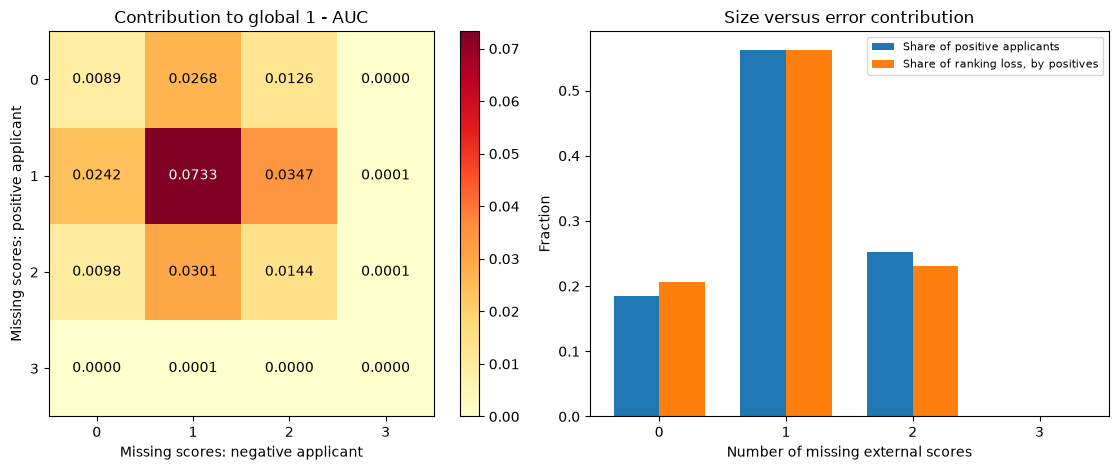

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
group='EXT_missing_count'
matrix=cells[cells.group==group].pivot(index='positive_group',columns='negative_group',values='global_auc_loss')
im=axes[0].imshow(matrix.to_numpy(),cmap='YlOrRd',vmin=0)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        axes[0].text(j,i,f'{matrix.iloc[i,j]:.4f}',ha='center',va='center',fontsize=10,color="white" if matrix.iloc[i,j]>.5*matrix.to_numpy().max() else "black")
axes[0].set(xticks=range(len(matrix.columns)),xticklabels=matrix.columns,yticks=range(len(matrix)),yticklabels=matrix.index,
    xlabel='Missing scores: negative applicant',ylabel='Missing scores: positive applicant',title='Contribution to global 1 - AUC')
fig.colorbar(im,ax=axes[0],fraction=.046)
frame=slices[slices.group==group].sort_values('value');xx=np.arange(len(frame))
axes[1].bar(xx-.18,frame.positives/frame.positives.sum(),.36,label='Share of positive applicants')
axes[1].bar(xx+.18,frame.positive_share_of_total_loss,.36,label='Share of ranking loss, by positives')
axes[1].set(xticks=xx,xticklabels=frame.value,xlabel='Number of missing external scores',ylabel='Fraction',title='Size versus error contribution')
axes[1].legend(fontsize=8);fig.tight_layout();fig.savefig(ART/'external_score_pair_loss.png',dpi=140);plt.show()

## Interpretation without a subgroup selection trap

The two-missing-score group has lower within-group AUC, but its share of
positive-centered global ranking loss is below its share of positive cases.
Its weaker within-group AUC alone does not establish that a specialist is the
best use of compute. Most cash-loan errors occur within a large population;
this is not evidence of a single small broken segment. Large groups' mean
calibration residuals are small. A global calibration adjustment is unlikely
to explain a large ranking jump.

In [4]:
display(slices[(~slices["sparse"])&(slices.group.isin(['NAME_INCOME_TYPE','NAME_EDUCATION_TYPE','age_band']))])
display(pd.Series(summary['saved_capacity_diagnostic']))

,group,value,rows,positives,negatives,positive_rate,mean_prediction,calibration_residual,auc,within_auc_loss,positive_centered_auc_loss,negative_centered_auc_loss,loss_involving_group,positive_share_of_total_loss,sparse
3,NAME_INCOME_TYPE,Commercial associate,32083,2403,29680,0.074899,0.074590,0.000309,0.753580,0.012625,0.056628,0.052257,0.096260,0.240769,False
5,NAME_INCOME_TYPE,Pensioner,24542,1321,23221,0.053826,0.052301,0.001525,0.735402,0.005830,0.044295,0.027995,0.066460,0.188332,False
6,NAME_INCOME_TYPE,State servant,9610,559,9051,0.058169,0.059346,-0.001177,0.773432,0.000823,0.015319,0.012221,0.026717,0.065133,False
9,NAME_INCOME_TYPE,Working,70706,6772,63934,0.095777,0.094795,0.000982,0.763959,0.073411,0.118892,0.142700,0.188181,0.505500,False
11,NAME_EDUCATION_TYPE,Higher education,33404,1767,31637,0.052898,0.052614,0.000284,0.764742,0.009447,0.054998,0.037139,0.082690,0.233836,False
12,NAME_EDUCATION_TYPE,Incomplete higher,4581,396,4185,0.086444,0.090195,-0.003751,0.749445,0.000298,0.007419,0.009305,0.016426,0.031543,False
13,NAME_EDUCATION_TYPE,Lower secondary,1692,191,1501,0.112884,0.098756,0.014128,0.738924,0.000054,0.003625,0.003471,0.007042,0.015414,False
14,NAME_EDUCATION_TYPE,Secondary / secondary special,97206,8702,88504,0.089521,0.088551,0.000971,0.758178,0.133783,0.169142,0.185169,0.220528,0.719151,False
30,age_band,"(-0.001, 30.0]",20093,2328,17765,0.115861,0.115859,0.000003,0.737915,0.007786,0.033661,0.050132,0.076007,0.143118,False
31,age_band,"(30.0, 40.0]",36691,3501,33190,0.095418,0.093914,0.001504,0.768400,0.019331,0.061101,0.073021,0.114791,0.259788,False


model                       improvements/round3/models/r3_cat_signed_s0_fo...
own_training_sample_rows                                                20000
heldout_rows                                                            34241
own_training_sample_auc                                              0.814093
heldout_auc                                                          0.765179
caution                     One saved model and a sampled training subset....
dtype: object

## Capacity and generalization

One saved CatBoost model has about 0.814 AUC on a deterministic sample of its
own training rows and 0.765 on its held-out rows. The in-sample number is
optimistic and is not a submission-quality estimate. This illustrates a
generalization gap, not the dataset's maximum attainable AUC. It gives little
justification for merely increasing depth without a better representation,
inductive bias or regularization strategy.

## Next hypotheses

Prioritize a scratch-trained TabM model with numerical embeddings and explicit
missingness; compare raw and the successful engineered representations. Test
selected fold-safe learned borrower/profile interactions alongside the same
reference tree learner, with a small declared pilot budget. Missing-score
reconstruction must first show out-of-fold auxiliary predictive quality and
downstream benefit; observed-score masking may not represent true missingness.
Specialists/retrieval and nested stacking remain conditional on measurable
signal and error complementarity. No larger seed bank is justified yet.

A substantial branch targets at least 0.002 OOF improvement before expensive
expansion. This is a compute-allocation target, not a promised score. All
confirmation remains on previously explored labels and must be labeled so.

In [5]:
protected=json.loads((ROOT/'improvements/round4/reference/preserved_hashes.json').read_text());checked=0
for name,want in protected.items():
    path=ROOT/name
    if path.exists():
        assert hashlib.sha256(path.read_bytes()).hexdigest()==want,name
        checked+=1
print('Unchanged protected files present:',checked)
display(Markdown((ROOT/'HIGH_UPSIDE_PLAN.md').read_text()))

Unchanged protected files present: 230


# Revised research priority: pursue substantial gains

Status: opportunity audit, after the user's November 9 priority change. The incremental
round-four search and its downstream controller have been stopped. Seven screens
completed; partial work and all evidence are retained. No new submission or
round-four validation conclusion has been produced. The current confirmed public
reference remains **0.76824**, `output/submission_round3_bagged.csv`.

## Target and evidence

Reaching 0.80000 requires **+0.03176 absolute public AUC**. This is an aspiration,
not a forecast. No measured upper bound on this dataset's attainable AUC exists.
Failure of several models does not establish a ceiling; neither does choosing a
larger architecture establish that the target is achievable.

The supplied README explicitly says this competition uses a subset of the original
Home Credit datasets. Local inventory contains only train, test and sample submission
CSVs; there are 32 supplied predictors. Scores or solutions using original history
tables are not directly comparable and those rows cannot be imported. Prior audit
train-versus-test classification AUC was 0.518898: this particular classifier found
little separation, not proof of identical distributions. Broad drift weighting is
therefore a lower priority without stronger slice-specific evidence.

The existing bank is tree-dominated. The two earlier neural experiments were small
scikit-learn MLP configurations, not a comprehensive test of modern tabular neural
methods. Existing categorical/group and ratio-feature tests also do not exhaust
carefully nested supervised representations. These are research gaps, not evidence
of a likely 0.03 gain.

## Ordered plan and reasons

1. **Locate an opportunity before another broad sweep.** Review current three-seed
   OOF errors against external-score availability, loan type, amount/annuity and
   applicant profiles. Quantify which sufficiently large slices contribute most
   ranking errors; lower slice AUC alone is not a reason to fit a specialist.
   Audit source-column definitions, invalid values, rounding structure and missing
   signals. Examine near-duplicate feature profiles without recovering identities
   or external labels. Compare per-slice ranking error and uncertainty, not just
   feature importance or mean calibration. Outcome: a small hypothesis list tied
   to a measurable error pattern; drop unsupported avenues.

2. **Test learned representations that differ from another arithmetic ratio.**
   Prioritize a small number of train-only, heavily regularized interaction-risk
   encodings and neighbor/profile summaries, motivated by step 1. Every supervised
   transform must be cross-fitted within the outer training fold; validation and
   test targets never enter any fit or reference pool. Compare each block at the
   same learner/settings to isolate its contribution. CatBoost already performs
   categorical target statistics, so ordinary target encoding alone is not assumed
   novel. Missing external-score reconstruction is conditional on demonstrable
   out-of-fold predictive quality and downstream ranking gains; never fabricate
   observed scores or treat imputation as additional ground truth.

3. **Test a substantially different model family, trained from scratch.** Start
   with a compact TabM model with numerical embeddings and explicit missingness,
   using the authors' documented implementation and citations. TabM shares weights
   across multiple jointly trained predictors; this is a materially different
   experiment from the earlier two MLPs. Compare raw and successful engineered
   representations, with a small declared optimization budget. A retrieval-based
   TabR experiment is conditional on usable neighbor signal and feasible runtime,
   rather than automatically launching another expensive architecture. All learned
   weights are initialized locally and trained only on supplied training rows.
   No pretrained checkpoints, downloaded benchmark datasets or external history.

4. **Use complementary models only after they earn the cost.** If a new family
   shows meaningful common-fold standalone or ensemble gains, evaluate a genuinely
   nested learned combiner or a model-learned segment gate. Segment specialists need
   enough positive cases and consistent held-out evidence. An outer validation
   row's target must be absent from every base fit, transform, neighbor pool and
   combiner fit. Do not stack already reused OOF predictions and call that fully
   nested. Do not add seed banks before a structural improvement is demonstrated.

## Compute and decision policy

The local machine reports ARM64 and eight logical CPUs; PyTorch is not installed
in the project venv. Any required software belongs in that venv, with versions and
licenses recorded. Installing software is distinct from adding external data.
Accelerator availability and one-model memory/runtime should be checked before a
large neural run. No cloud resources, costs or data transfers are assumed authorized.

The experiment unit is a new hypothesis/representation/model family, not a list of
nearby hyperparameters. Begin with matched inexpensive pilots and learning curves;
allocate full validation only to useful evidence. Aim for **0.002 or more absolute
OOF gain** for a substantial branch. This is a budget/promotion target, not a
prediction of attainable gain. Small gains can be retained cheaply but should not
trigger hours of further tuning or larger banks under the new priority. Freeze
the exact metric rules and full combination grid before new confirmation fits.

Use the current complete three-seed reference and matching row/fold groups. Fresh
partitions test robustness on previously explored labels; no retrospective split
can be presented as an untouched test. Require direction and slice/fold consistency,
report uncertainty and distinguish selection from confirmation. Public scores
measure final candidates; they do not select dozens of configurations.

Before fitting, record exact pilot specs, fold membership, compute limits, early
stopping and promotion criteria in a new notebook and machine-readable plan. Keep
every existing notebook and submission unchanged. Continue the why/how/negative
result journal, local-venv execution and saved-model reproduction requirements.

## Leaderboard context supplied by the user

The user reports that the top ten have displayed scores of 1 and the top twenty
are above 0.8. The user is uncertain whether external data was used. This is
user-reported leaderboard context, not independently verified score provenance.
It makes 0.8+ a relevant competitive target, but does not establish that those
scores are achievable using only the allowed columns and labels. No inference
of misconduct is made. Public-subset ranking is distinct from full/private-test
performance. These observations do not change the data restrictions, validation
rules or model-selection weights.

## Method references (code/methods only; no datasets or weights fetched)

- [Official TabM implementation and training guidance](https://github.com/yandex-research/tabm).
- [Official TabR implementation](https://github.com/yandex-research/tabular-dl-tabr).

These references establish how the candidate architectures work, not that either
will outperform the current bank on this competition.


In [6]:
RUN_AUDIT=False
if RUN_AUDIT:
    sys.path.insert(0,str(HERE))
    import opportunity_audit
    opportunity_audit.run()